In [3]:
# NOTEBOOK 17: WEBQSP + CWQ FINAL PAPER RESULTS
# Runtime: CPU
# Reads completed experiments. No training or model inference.

import importlib.metadata as metadata
import os
import subprocess
import sys

from google.colab import drive

drive.mount("/content/drive")

# Install only missing plotting dependencies.
# A fresh subprocess below avoids stale Matplotlib imports.
missing = []
for package in ["numpy", "matplotlib", "pillow"]:
    try:
        metadata.version(package)
    except metadata.PackageNotFoundError:
        missing.append(package)

if missing:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", *missing],
        check=True,
    )

PROGRAM = r"""
import collections
import csv
import hashlib
import json
import math
import os
import time
import zipfile
from pathlib import Path

import numpy as np
import matplotlib

matplotlib.use("Agg")

import matplotlib.pyplot as plt
from PIL import Image


ROOT = Path(
    os.environ.get(
        "SETSTOP_PROJECT_ROOT",
        "/content/drive/MyDrive/SetStop_KGQA",
    )
)
OUT = ROOT / "outputs/two_dataset_paper_results_v1"
CODE_VERSION = "setstop_two_dataset_paper_v1_0"

START = time.time()
SOURCES = {}
AUDIT = []


def file_hash(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024**2), b""):
            digest.update(block)
    return digest.hexdigest()


def read_json(path):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing completed-experiment file: {path}"
        )
    SOURCES[str(path)] = file_hash(path)
    return json.loads(path.read_text(encoding="utf-8"))


def read_csv(path):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing completed-experiment CSV: {path}"
        )
    SOURCES[str(path)] = file_hash(path)

    with open(path, encoding="utf-8", newline="") as file:
        return list(csv.DictReader(file))


def write_text(path, text):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".partial")
    temporary.write_text(text, encoding="utf-8")
    temporary.replace(path)


def save_json(path, obj):
    write_text(
        path,
        json.dumps(
            obj,
            indent=2,
            ensure_ascii=False,
            allow_nan=False,
        ) + "\n",
    )


def write_csv(path, rows):
    if not rows:
        raise ValueError(f"Cannot write an empty table: {path}")

    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".partial")

    with open(
        temporary,
        "w",
        encoding="utf-8",
        newline="",
    ) as file:
        writer = csv.DictWriter(
            file,
            fieldnames=list(rows[0]),
        )
        writer.writeheader()
        writer.writerows(rows)

    temporary.replace(path)


def check(condition, message):
    if not condition:
        raise ValueError(message)


def close(a, b, message):
    check(
        math.isclose(
            float(a),
            float(b),
            rel_tol=0,
            abs_tol=1e-10,
        ),
        message,
    )


def find_external_summary():
    candidates = []

    for base in [
        ROOT / "outputs",
        ROOT / "external_baselines",
    ]:
        if base.exists():
            candidates.extend(
                base.rglob("external_baseline_summary_v1.json")
            )

    candidates = sorted(set(candidates))

    check(
        bool(candidates),
        "Cannot find external_baseline_summary_v1.json "
        "under this project.",
    )
    check(
        len({file_hash(path) for path in candidates}) == 1,
        "Different external-baseline summaries exist. "
        "Resolve the conflicting copies first.",
    )

    return candidates[0]


def verify_inventory(directory, names, required=False):
    path = directory / "artifact_inventory_v1.json"

    if not path.exists():
        check(
            not required,
            f"Missing inventory: {path}",
        )
        AUDIT.append(
            f"No inventory available in {directory}; "
            "input hashes are recorded."
        )
        return

    inventory = read_json(path)

    # Earlier notebooks used "artifacts"; later notebooks used "files".
    raw_entries = inventory.get(
        "files",
        inventory.get("artifacts"),
    )

    check(
        isinstance(raw_entries, list),
        f"Unsupported inventory format: {path}",
    )

    entries = {
        entry.get("name") or Path(entry["path"]).name: entry
        for entry in raw_entries
    }

    for name in names:
        check(
            name in entries,
            f"Inventory has no entry for {name}",
        )

        file = directory / name
        entry = entries[name]

        check(
            file.exists()
            and file.stat().st_size == entry["bytes"]
            and file_hash(file) == entry["sha256"],
            f"Inventory mismatch: {file}",
        )

    AUDIT.append(
        f"Inventory verified: {directory.name}"
    )


METRICS = [
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "micro_f1",
    "exact_match",
    "complete_recall",
    "mean_actions",
    "mean_retrieved_edges",
]


def metric_row(
    dataset,
    method,
    values,
    n,
    cap=None,
    setting="Sequential search",
):
    row = dict(
        dataset=dataset,
        method=method,
        setting=setting,
        questions=n,
        maximum_action_cap=cap,
    )

    for key in METRICS:
        value = values.get(key)
        row[key] = None if value is None else float(value)

        check(
            value is None or math.isfinite(row[key]),
            f"Nonfinite {key}: {method}",
        )

        if key not in [
            "mean_actions",
            "mean_retrieved_edges",
        ]:
            check(
                value is not None and 0 <= row[key] <= 1,
                f"Invalid {key}: {method}",
            )

    return row


def old_e2e_values(report):
    # WebQSP's original evaluation used nested mean fields.
    return dict(
        macro_precision=report["precision"]["mean"],
        macro_recall=report["recall"]["mean"],
        macro_f1=report["answer_f1"]["mean"],
        micro_f1=report["micro_f1"],
        exact_match=report["exact_match"]["mean"],
        complete_recall=report["complete_recall"]["mean"],
        mean_actions=report["actions"]["mean"],
        mean_retrieved_edges=report["retrieved_edges"]["mean"],
    )


def old_interval(pair, key):
    value = pair["metrics"][key]

    return dict(
        difference=float(
            value["mean_difference_first_minus_second"]
        ),
        ci95=[
            float(value["ci95_lower"]),
            float(value["ci95_upper"]),
        ],
    )


def latex_escape(value):
    mapping = {
        "&": r"\&",
        "%": r"\%",
        "$": r"\$",
        "#": r"\#",
        "_": r"\_",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
        "\\": r"\textbackslash{}",
    }
    return "".join(
        mapping.get(character, character)
        for character in str(value)
    )


def fmt(value, digits=3):
    return (
        "--"
        if value is None
        else f"{float(value):.{digits}f}"
    )


print("=" * 100)
print("NOTEBOOK 17: WEBQSP AND CWQ FINAL PAPER RESULTS")
print("=" * 100)
print(
    "Runtime: CPU. No model loading, training, inference, "
    "or threshold selection."
)
print("Output directory:", OUT, flush=True)

web_dir = ROOT / "outputs/cost_matched_ablation_v1"
web_final_dir = ROOT / "outputs/final_paper_analysis_v1"
cwq_dir = ROOT / "outputs/cwq_test_evaluation_v1"

web = read_json(
    web_dir / "cost_matched_ablation_summary_v1.json"
)
web_paired = read_json(
    web_dir / "paired_bootstrap_cost_matched_v1.json"
)
web_budget = read_csv(
    web_dir / "test_budget_results_v1.csv"
)
web_final = read_json(
    web_final_dir / "final_paper_analysis_summary_v1.json"
)
web_e2e = read_json(
    ROOT
    / "outputs/end_to_end_test_v1/end_to_end_summary_v1.json"
)
external = read_json(find_external_summary())

cwq = read_json(
    cwq_dir / "cwq_test_summary_v1.json"
)
cwq_paired = read_json(
    cwq_dir / "cwq_test_paired_comparisons_v1.json"
)

verify_inventory(
    web_dir,
    [
        "cost_matched_ablation_summary_v1.json",
        "paired_bootstrap_cost_matched_v1.json",
        "test_budget_results_v1.csv",
    ],
)
verify_inventory(
    web_final_dir,
    ["final_paper_analysis_summary_v1.json"],
)
verify_inventory(
    cwq_dir,
    [
        "cwq_test_summary_v1.json",
        "cwq_test_paired_comparisons_v1.json",
        "cwq_test_per_question_v1.jsonl",
    ],
    required=True,
)

check(
    web["status"] == "completed"
    and web["regression_check"]["status"] == "PASS"
    and web_final["notebook06_regression_check"]["status"]
    == "PASS",
    "WebQSP regression/completion checks failed.",
)
check(
    web["data"]["test_questions"]
    == web_final["test_questions"]
    == 736,
    "WebQSP question count changed.",
)
check(
    cwq["test_questions"]
    == cwq_paired["questions"]
    == 495,
    "CWQ question count changed.",
)
check(
    cwq["signature"] == cwq_paired["signature"]
    and cwq["data_signature"]
    == cwq_paired["data_signature"],
    "CWQ report signatures disagree.",
)
check(
    cwq["notebook15_regression_passed"]
    and cwq["shared_prefix_checks_passed"]
    and not cwq["gold_used_for_policy"]
    and not cwq["test_used_for_selection"],
    "CWQ frozen-evaluation checks failed.",
)
check(
    cwq["settings"]
    == dict(
        max_hops=4,
        frontier_limit=128,
        action_cap=24,
        controller_threshold=0.853,
        answer_threshold=0.96,
        matched_budget=14,
    ),
    "CWQ operating point changed.",
)

web_cfg = web["frozen_configuration"]

close(
    web_cfg["controller_threshold"],
    0.71,
    "WebQSP controller threshold changed.",
)
close(
    web_cfg["answer_threshold"],
    0.67,
    "WebQSP answer threshold changed.",
)
check(
    web_cfg["maximum_hops"] == 3
    and web_cfg["maximum_frontier_candidates"] == 16,
    "WebQSP hop/frontier configuration changed.",
)
check(
    web["reporting_protocol"]["action_matched_comparator"]
    .endswith("cap 6"),
    "Unexpected WebQSP matched comparator.",
)

# Recompute CWQ metrics from saved answer sets.
# This is report verification, not model inference.
path = cwq_dir / "cwq_test_per_question_v1.jsonl"
SOURCES[str(path)] = file_hash(path)

cwq_groups = collections.defaultdict(dict)

with open(path, encoding="utf-8") as file:
    for line in file:
        if not line.strip():
            continue

        row = json.loads(line)
        qid = row["qid"]
        policy = row["policy"]

        check(
            qid not in cwq_groups[policy],
            f"Duplicate CWQ record: {qid}, {policy}",
        )

        predicted = set(row["predicted_answers"])
        gold = set(row["gold_answers"])

        tp = len(predicted & gold)
        fp = len(predicted - gold)
        fn = len(gold - predicted)

        check(
            (tp, fp, fn)
            == (
                row["true_positive_count"],
                row["false_positive_count"],
                row["false_negative_count"],
            ),
            f"CWQ answer counts disagree: {qid}",
        )

        close(
            row["precision"],
            tp / max(1, len(predicted)),
            f"CWQ precision mismatch: {qid}",
        )
        close(
            row["recall"],
            tp / len(gold),
            f"CWQ recall mismatch: {qid}",
        )
        close(
            row["answer_f1"],
            2 * tp / (len(predicted) + len(gold)),
            f"CWQ F1 mismatch: {qid}",
        )

        check(
            row["exact_match"] == int(predicted == gold)
            and row["complete_recall"]
            == int(gold <= predicted),
            f"CWQ set metrics disagree: {qid}",
        )
        check(
            fn
            == row["missed_by_search_count"]
            + row["visited_gold_not_predicted_count"],
            f"CWQ false-negative decomposition mismatch: {qid}",
        )

        cwq_groups[policy][qid] = row

check(
    set(cwq_groups) == set(cwq["methods"])
    and sum(map(len, cwq_groups.values())) == 2475,
    "Expected five CWQ methods and 2475 records.",
)

cwq_qids = set(next(iter(cwq_groups.values())))

check(
    len(cwq_qids) == 495
    and all(
        set(group) == cwq_qids
        for group in cwq_groups.values()
    ),
    "CWQ methods do not share the same test questions.",
)

qid_hash = hashlib.sha256(
    json.dumps(
        sorted(cwq_qids),
        sort_keys=True,
    ).encode()
).hexdigest()

check(
    qid_hash == cwq["test_qid_sha256"],
    "CWQ question-set hash changed.",
)

metric_keys = {
    "macro_precision": "precision",
    "macro_recall": "recall",
    "macro_f1": "answer_f1",
    "exact_match": "exact_match",
    "complete_recall": "complete_recall",
    "mean_actions": "actions",
    "mean_retrieved_edges": "retrieved_edges",
}

for policy, group in cwq_groups.items():
    for report_key, row_key in metric_keys.items():
        close(
            cwq["methods"][policy][report_key],
            np.mean([
                row[row_key]
                for row in group.values()
            ]),
            f"CWQ summary mismatch: {policy}, {report_key}",
        )

    tp, fp, fn = [
        sum(row[key] for row in group.values())
        for key in [
            "true_positive_count",
            "false_positive_count",
            "false_negative_count",
        ]
    ]

    close(
        cwq["methods"][policy]["micro_f1"],
        2 * tp / (2 * tp + fp + fn),
        f"CWQ micro-F1 mismatch: {policy}",
    )

AUDIT.append(
    "All 2475 CWQ per-question records and "
    "macro/micro point estimates verified."
)

# Preserve every predefined WebQSP budget configuration.
budget_index = {
    (row["policy"], int(row["budget_cap"])): row
    for row in web_budget
}

check(
    len(web_budget) == len(budget_index) == 18,
    "Expected 18 unique WebQSP budget configurations.",
)
check(
    set(budget_index)
    == {
        (policy, budget)
        for policy in [
            "relation_fixed",
            "learned_ranker_fixed",
            "setstop",
        ]
        for budget in [2, 4, 6, 8, 10, 12]
    },
    "WebQSP budget grid changed.",
)
check(
    all(
        int(row["questions"]) == 736
        and row["split"] == "test"
        for row in web_budget
    ),
    "WebQSP budget table has inconsistent split/counts.",
)

web_primary = web["primary_cost_matched_test_comparison"]
web_ci = web_paired["test"][
    "primary_cost_matched_vs_learned"
]

check(
    web_ci["questions"] == 736
    and web_ci["second"]["budget_cap"] == 6
    and web_ci["first"]["budget_cap"] == 12,
    "WebQSP paired comparison is not the intended "
    "cap-6 comparison.",
)

for key in METRICS:
    close(
        web_primary["first"][key],
        budget_index[("setstop", 12)][key],
        f"WebQSP SetStop mismatch: {key}",
    )
    close(
        web_primary["second"][key],
        budget_index[("learned_ranker_fixed", 6)][key],
        f"WebQSP fixed-cap-6 mismatch: {key}",
    )
    close(
        web_primary["first"][key],
        web_final["primary_cost_matched_result"]["first"][key],
        f"Notebook 10 WebQSP result differs: {key}",
    )
    close(
        web_primary["first"][key],
        old_e2e_values(web_e2e["setstop_e2e"])[key],
        f"Original WebQSP SetStop result differs: {key}",
    )

AUDIT.append(
    "WebQSP saved summaries, cap-6 comparison, "
    "and original SetStop metrics agree."
)

interval_map = {
    "macro_f1": "answer_f1",
    "macro_precision": "precision",
    "macro_recall": "recall",
    "exact_match": "exact_match",
    "complete_recall": "complete_recall",
    "mean_actions": "actions",
    "mean_retrieved_edges": "retrieved_edges",
}

comparisons = {}

comparison_inputs = [
    (
        "WebQSP",
        web_primary["first"],
        web_primary["second"],
        {
            key: old_interval(web_ci, old_key)
            for key, old_key in interval_map.items()
        },
        736,
    ),
    (
        "CWQ",
        cwq["methods"]["setstop_e2e"],
        cwq["methods"]["model_fixed_b14_e2e"],
        cwq_paired["comparisons"]["model_fixed_b14_e2e"],
        495,
    ),
]

for dataset, first, second, intervals, n in comparison_inputs:
    for key in interval_map:
        close(
            intervals[key]["difference"],
            first[key] - second[key],
            f"{dataset} paired difference mismatch: {key}",
        )

        lower, upper = intervals[key]["ci95"]

        check(
            math.isfinite(lower)
            and math.isfinite(upper)
            and lower <= upper,
            f"Invalid {dataset} confidence interval.",
        )

    comparisons[dataset] = dict(
        questions=n,
        setstop={
            key: float(first[key])
            for key in METRICS
        },
        fixed_ranker={
            key: float(second[key])
            for key in METRICS
        },
        differences=intervals,
        matching=(
            "Approximately matched mean actions; "
            "edge costs are reported separately."
        ),
    )

# Include stronger external baselines without treating them
# as cost-matched sequential-search methods.
main_rows = []

for policy, cap, name in [
    ("relation_fixed", 6, "Relation fixed (cap 6)"),
    ("relation_fixed", 12, "Relation fixed (cap 12)"),
    ("learned_ranker_fixed", 6, "Learned ranker (cap 6)"),
    ("learned_ranker_fixed", 12, "Learned ranker (cap 12)"),
    ("setstop", 12, "SetStop (max 12)"),
]:
    main_rows.append(
        metric_row(
            "WebQSP",
            name,
            budget_index[(policy, cap)],
            736,
            cap,
        )
    )

check(
    web_e2e["oracle_rank_e2e"]["questions"] == 736,
    "Oracle diagnostic question count changed.",
)

main_rows.append(
    metric_row(
        "WebQSP",
        "Oracle ranker",
        old_e2e_values(web_e2e["oracle_rank_e2e"]),
        736,
        12,
        "Gold-based ranking diagnostic",
    )
)

full_edges = float(
    web_final["external_graph_exposure"][
        "full_graph_baseline_mean_edges"
    ]
)

for name in ["NSM+h", "ReaRev"]:
    report = external[name]

    check(
        report["threshold_selection_split"] == "development",
        f"{name} threshold provenance changed.",
    )

    values = dict(
        report["test_metrics_at_selected_epsilon"]
    )

    check(
        values["questions"] == 736,
        f"{name} test question count changed.",
    )

    values.update(
        mean_actions=None,
        mean_retrieved_edges=full_edges,
    )

    main_rows.append(
        metric_row(
            "WebQSP",
            name,
            values,
            736,
            None,
            "Full question graph",
        )
    )

cwq_labels = {
    "relation_fixed_b14_e2e": "Relation fixed (cap 14)",
    "relation_fixed_e2e": "Relation fixed (cap 24)",
    "model_fixed_b14_e2e": "Learned ranker (cap 14)",
    "model_fixed_e2e": "Learned ranker (cap 24)",
    "setstop_e2e": "SetStop (max 24)",
}

for policy, label in cwq_labels.items():
    main_rows.append(
        metric_row(
            "CWQ",
            label,
            cwq["methods"][policy],
            495,
            14 if "b14" in policy else 24,
        )
    )

settings_rows = [
    dict(
        dataset="WebQSP",
        test_questions=736,
        max_hops=3,
        frontier_limit=16,
        maximum_action_cap=12,
        fixed_reference_cap=6,
        controller_threshold=float(
            web_cfg["controller_threshold"]
        ),
        answer_threshold=float(
            web_cfg["answer_threshold"]
        ),
    ),
    dict(
        dataset="CWQ",
        test_questions=495,
        max_hops=4,
        frontier_limit=128,
        maximum_action_cap=24,
        fixed_reference_cap=14,
        controller_threshold=0.853,
        answer_threshold=0.96,
    ),
]

matched_rows = []

for dataset, data in comparisons.items():
    differences = data["differences"]

    row = dict(
        dataset=dataset,
        questions=data["questions"],
        fixed_ranker_macro_f1=data["fixed_ranker"]["macro_f1"],
        setstop_macro_f1=data["setstop"]["macro_f1"],
    )

    for key in [
        "macro_f1",
        "exact_match",
        "complete_recall",
    ]:
        row[key + "_difference_pp"] = (
            100 * differences[key]["difference"]
        )
        row[key + "_ci95_lower_pp"] = (
            100 * differences[key]["ci95"][0]
        )
        row[key + "_ci95_upper_pp"] = (
            100 * differences[key]["ci95"][1]
        )

    for key in [
        "mean_actions",
        "mean_retrieved_edges",
    ]:
        row["fixed_" + key] = data["fixed_ranker"][key]
        row["setstop_" + key] = data["setstop"][key]
        row[key + "_difference"] = (
            differences[key]["difference"]
        )
        row[key + "_ci95_lower"] = (
            differences[key]["ci95"][0]
        )
        row[key + "_ci95_upper"] = (
            differences[key]["ci95"][1]
        )

    matched_rows.append(row)

OUT.mkdir(parents=True, exist_ok=True)

TABLES = OUT / "tables"
FIGURES = OUT / "figures"
TEXT = OUT / "text"

for directory in [TABLES, FIGURES, TEXT]:
    directory.mkdir(parents=True, exist_ok=True)

write_csv(
    OUT / "combined_results_v1.csv",
    main_rows,
)
write_csv(
    OUT / "matched_budget_comparison_v1.csv",
    matched_rows,
)
write_csv(
    OUT / "evaluation_settings_v1.csv",
    settings_rows,
)
write_csv(
    OUT / "webqsp_all_budget_results_v1.csv",
    web_budget,
)
save_json(
    OUT / "matched_budget_comparisons_v1.json",
    comparisons,
)

# Main results table.
lines = [
    r"\begin{table*}[t]",
    r"\centering",
    r"\small",
    r"\begin{tabular}{llrrrrrr}",
    r"\toprule",
    r"Dataset & Method & F1 & Micro-F1 & EM & CR & Actions & Edges \\",
    r"\midrule",
]

previous_dataset = None

for row in main_rows:
    if (
        previous_dataset is not None
        and row["dataset"] != previous_dataset
    ):
        lines.append(r"\midrule")

    dataset = (
        latex_escape(row["dataset"])
        if row["dataset"] != previous_dataset
        else ""
    )
    name = latex_escape(row["method"])

    if row["method"].startswith("SetStop"):
        name = r"\textbf{" + name + "}"

    lines.append(
        " & ".join([
            dataset,
            name,
            fmt(row["macro_f1"]),
            fmt(row["micro_f1"]),
            fmt(row["exact_match"]),
            fmt(row["complete_recall"]),
            fmt(row["mean_actions"], 2),
            fmt(row["mean_retrieved_edges"], 1),
        ]) + r" \\"
    )

    previous_dataset = row["dataset"]

lines += [
    r"\bottomrule",
    r"\end{tabular}",
    (
        r"\caption{Results on selected multi-answer test subsets: "
        r"WebQSP ($n=736$) and CWQ ($n=495$). "
        r"F1 is macro answer-set F1; EM is exact set match; "
        r"CR is complete-answer recall. Actions and edges are means. "
        r"SetStop uses adaptive stopping up to its maximum cap. "
        r"NSM+h and ReaRev process the full question graph and "
        r"were evaluated only on WebQSP. "
        r"The oracle ranker uses gold-based ranking and is a diagnostic. "
        r"Edge counts are a structural proxy, not FLOPs or latency.}"
    ),
    r"\label{tab:two_dataset_results}",
    r"\end{table*}",
]

write_text(
    TABLES / "two_dataset_results_v1.tex",
    "\n".join(lines) + "\n",
)

# Paired matched-budget comparison table.
lines = [
    r"\begin{table*}[t]",
    r"\centering",
    r"\small",
    r"\begin{tabular}{lrlrlrl}",
    r"\toprule",
    (
        r"Dataset & $\Delta$F1 & 95\% CI & "
        r"$\Delta$EM & 95\% CI & $\Delta$CR & 95\% CI \\"
    ),
    r"\midrule",
]

for dataset, data in comparisons.items():
    values = [dataset]

    for key in [
        "macro_f1",
        "exact_match",
        "complete_recall",
    ]:
        value = data["differences"][key]

        values += [
            f'{100 * value["difference"]:+.2f}',
            (
                f'[{100 * value["ci95"][0]:+.2f}, '
                f'{100 * value["ci95"][1]:+.2f}]'
            ),
        ]

    lines.append(" & ".join(values) + r" \\")

lines += [
    r"\bottomrule",
    r"\end{tabular}",
    (
        r"\caption{SetStop minus the learned fixed-budget ranker "
        r"at approximately matched mean action costs. "
        r"Differences and paired bootstrap intervals are in percentage points. "
        r"Fixed caps are 6 for WebQSP and 14 for CWQ; "
        r"SetStop averages 5.95 and 14.12 actions, respectively. "
        r"The comparison does not enforce equal edge costs.}"
    ),
    r"\label{tab:two_dataset_matched}",
    r"\end{table*}",
]

write_text(
    TABLES / "two_dataset_matched_v1.tex",
    "\n".join(lines) + "\n",
)

# Frozen evaluation settings table.
lines = [
    r"\begin{table*}[t]",
    r"\centering",
    r"\small",
    r"\begin{tabular}{lrrrrrrr}",
    r"\toprule",
    (
        r"Dataset & Test $n$ & Hops & Frontier & Max cap & "
        r"Fixed cap & $\tau_c$ & $\tau_a$ \\"
    ),
    r"\midrule",
]

for row in settings_rows:
    lines.append(
        " & ".join([
            row["dataset"],
            str(row["test_questions"]),
            str(row["max_hops"]),
            str(row["frontier_limit"]),
            str(row["maximum_action_cap"]),
            str(row["fixed_reference_cap"]),
            fmt(row["controller_threshold"]),
            fmt(row["answer_threshold"]),
        ]) + r" \\"
    )

lines += [
    r"\bottomrule",
    r"\end{tabular}",
    (
        r"\caption{Dataset-specific frozen evaluation settings. "
        r"$\tau_c$ and $\tau_a$ denote the continuation and "
        r"answer-recognition thresholds. Separate controllers and "
        r"answer recognizers are trained for the two datasets. "
        r"Fixed cap denotes the action-reference comparison.}"
    ),
    r"\label{tab:two_dataset_settings}",
    r"\end{table*}",
]

write_text(
    TABLES / "two_dataset_settings_v1.tex",
    "\n".join(lines) + "\n",
)

# Figure: paired F1 improvements with their paired confidence intervals.
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

datasets = list(comparisons)

values = np.array([
    100 * comparisons[dataset]["differences"]["macro_f1"][
        "difference"
    ]
    for dataset in datasets
])
lower = np.array([
    100 * comparisons[dataset]["differences"]["macro_f1"][
        "ci95"
    ][0]
    for dataset in datasets
])
upper = np.array([
    100 * comparisons[dataset]["differences"]["macro_f1"][
        "ci95"
    ][1]
    for dataset in datasets
])

figure, axis = plt.subplots(
    figsize=(3.35, 2.55),
    layout="constrained",
)
positions = np.arange(len(datasets))

axis.bar(
    positions,
    values,
    width=0.48,
    color=["#2864A5", "#9254A1"],
    zorder=3,
)
axis.errorbar(
    positions,
    values,
    yerr=np.vstack([
        values - lower,
        upper - values,
    ]),
    fmt="none",
    ecolor="#202020",
    capsize=4,
    elinewidth=1.2,
    capthick=1.2,
    zorder=4,
)

for index, value in enumerate(values):
    axis.text(
        index,
        upper[index] + 0.40,
        f"{value:+.2f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

axis.set_xticks(
    positions,
    [
        f'{dataset}\n(n={comparisons[dataset]["questions"]})'
        for dataset in datasets
    ],
)
axis.set_ylabel(
    "Macro-F1 improvement\n(percentage points)"
)
axis.set_ylim(
    min(0, float(lower.min()) - 1),
    max(12, float(upper.max()) + 2),
)
axis.set_xlim(-0.65, len(datasets) - 0.35)
axis.axhline(
    0,
    color="#333333",
    linewidth=0.8,
)
axis.set_axisbelow(True)
axis.yaxis.grid(
    True,
    color="#DDDDDD",
    linewidth=0.6,
)
axis.spines[["top", "right"]].set_visible(False)

png_path = FIGURES / "matched_budget_f1_improvements_v1.png"
pdf_path = FIGURES / "matched_budget_f1_improvements_v1.pdf"

figure.savefig(
    png_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white",
)

figure_export = "vector PDF"

try:
    figure.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white",
    )
except Exception as error:
    # Preserve the figure if the Matplotlib PDF backend fails.
    figure_export = "Raster PDF fallback from 400-DPI PNG"

    with Image.open(png_path) as image:
        image.convert("RGB").save(
            pdf_path,
            format="PDF",
            resolution=400,
        )

    AUDIT.append(
        f"PDF backend fallback: "
        f"{type(error).__name__}: {error}"
    )
    print(
        "PDF backend unavailable; "
        "high-resolution PNG converted to PDF."
    )

plt.close(figure)

figure_tex = r'''\begin{figure}[t]
\centering
\includegraphics[width=\linewidth]{figures/matched_budget_f1_improvements_v1.pdf}
\caption{Macro-F1 improvements over the learned fixed-budget ranker at approximately matched action costs. Error bars show paired bootstrap 95\% confidence intervals for the differences. Results concern the selected multi-answer test subsets.}
\label{fig:two_dataset_gain}
\end{figure}
'''

write_text(
    TEXT / "two_dataset_figure_v1.tex",
    figure_tex,
)

# Generate concise result and discussion paragraphs.
web_comparison = comparisons["WebQSP"]
cwq_comparison = comparisons["CWQ"]

web_setstop = web_comparison["setstop"]
cwq_setstop = cwq_comparison["setstop"]
web_fixed = web_comparison["fixed_ranker"]
cwq_fixed = cwq_comparison["fixed_ranker"]

web_difference = web_comparison["differences"]
cwq_difference = cwq_comparison["differences"]

cwq_fixed24 = cwq["methods"]["model_fixed_e2e"]

action_saving = (
    100
    * (
        cwq_fixed24["mean_actions"]
        - cwq_setstop["mean_actions"]
    )
    / cwq_fixed24["mean_actions"]
)
edge_saving = (
    100
    * (
        cwq_fixed24["mean_retrieved_edges"]
        - cwq_setstop["mean_retrieved_edges"]
    )
    / cwq_fixed24["mean_retrieved_edges"]
)

search_misses = sum(
    row["missed_by_search_count"]
    for row in cwq_groups["setstop_e2e"].values()
)
all_misses = sum(
    row["false_negative_count"]
    for row in cwq_groups["setstop_e2e"].values()
)
miss_fraction = search_misses / max(1, all_misses)

f1_supported = all(
    data["differences"]["macro_f1"]["ci95"][0] > 0
    for data in comparisons.values()
)
em_supported = all(
    data["differences"]["exact_match"]["ci95"][0] > 0
    for data in comparisons.values()
)
cr_inconclusive = all(
    data["differences"]["complete_recall"]["ci95"][0]
    <= 0
    <= data["differences"]["complete_recall"]["ci95"][1]
    for data in comparisons.values()
)

check(
    f1_supported and em_supported and cr_inconclusive,
    "Results differ from the reviewed experiments. "
    "Review generated-paper wording before proceeding.",
)

results_text = (
    r"\paragraph{Approximately matched action budgets.}" + "\n"
    r"Table~\ref{tab:two_dataset_matched} compares SetStop "
    r"with the same learned ranker using a fixed budget. "
    f'On WebQSP, macro F1 increases from '
    f'{web_fixed["macro_f1"]:.3f} to '
    f'{web_setstop["macro_f1"]:.3f}, '
    f'a gain of '
    f'{100 * web_difference["macro_f1"]["difference"]:.2f} '
    f'percentage points '
    f'(paired 95\\% CI: '
    f'[{100 * web_difference["macro_f1"]["ci95"][0]:.2f}, '
    f'{100 * web_difference["macro_f1"]["ci95"][1]:.2f}]). '
    f'On CWQ, it increases from '
    f'{cwq_fixed["macro_f1"]:.3f} to '
    f'{cwq_setstop["macro_f1"]:.3f}, '
    f'a gain of '
    f'{100 * cwq_difference["macro_f1"]["difference"]:.2f} '
    f'points '
    f'(CI: '
    f'[{100 * cwq_difference["macro_f1"]["ci95"][0]:.2f}, '
    f'{100 * cwq_difference["macro_f1"]["ci95"][1]:.2f}]). '
    f'Exact match improves by '
    f'{100 * web_difference["exact_match"]["difference"]:.2f} '
    f'and '
    f'{100 * cwq_difference["exact_match"]["difference"]:.2f} '
    f'points, respectively. '
    "The complete-recall intervals include zero on both datasets.\n\n"
    r"\paragraph{Larger fixed budgets.}" + "\n"
    f'Compared with the 24-action CWQ ranker, SetStop uses '
    f'{action_saving:.1f}\\% fewer actions '
    f'and exposes {edge_saving:.1f}\\% fewer edges. '
    f'Its macro F1 is {cwq_setstop["macro_f1"]:.3f}, '
    f'compared with {cwq_fixed24["macro_f1"]:.3f}, '
    f'while complete recall falls from '
    f'{cwq_fixed24["complete_recall"]:.3f} to '
    f'{cwq_setstop["complete_recall"]:.3f}. '
    "The F1 interval crosses zero and does not establish "
    "equivalent performance. "
    r"NSM+h and ReaRev remain substantially more accurate "
    r"on WebQSP (Table~\ref{tab:two_dataset_results})." + "\n"
)

write_text(
    TEXT / "two_dataset_results_v1.tex",
    results_text,
)

discussion_text = (
    r"\paragraph{Interpretation and limits.}" + "\n"
    "The matched-budget comparisons support adaptive allocation "
    "of search effort: SetStop improves F1 and exact match on "
    "both datasets without establishing a complete-recall gain. "
    "Higher fixed budgets recover more complete sets, whereas "
    "stopping can prevent additional false positives. "
    f"On CWQ, {100 * miss_fraction:.1f}\\% of missed gold answers "
    "were never visited, locating most false negatives in search "
    "coverage rather than rejection of already visited answers. "
    "This does not isolate the cause, because recognition errors "
    "can also affect later search decisions. "
    "The experiments use selected multi-answer subsets with gold "
    "answers present in the supplied graph, separately trained "
    "models, and one training seed. Graph exposure is a structural "
    "proxy, not a measurement of neural compute or latency. "
    "The reported intervals cover question sampling, "
    "not training variability.\n"
)

write_text(
    TEXT / "two_dataset_discussion_v1.tex",
    discussion_text,
)

usage = '''Copy the tables/, figures/, and text/ folders into your ACL project.
Keep your existing document class, ACL style options, fonts, margins, and bibliography.
The snippets use booktabs and graphicx, as in the previous tables and figures.

Insert in the existing Results section:
\\input{tables/two_dataset_results_v1.tex}
\\input{tables/two_dataset_matched_v1.tex}
\\input{text/two_dataset_figure_v1.tex}

Use tables/two_dataset_settings_v1.tex in Experimental Setup or the appendix if needed.
Replace outdated result paragraphs with text/two_dataset_results_v1.tex.
Use text/two_dataset_discussion_v1.tex to update the existing Discussion.

These files do not create or overwrite a main paper or its preamble.
Do not include both old and new result paragraphs if they duplicate the same findings.
Retain previous budget sweeps and stronger-baseline comparisons where relevant.
NSM+h and ReaRev were evaluated only on WebQSP; no CWQ scores are fabricated.
The figure shows confidence intervals of paired DIFFERENCES, not individual model F1.
Do not use the cached Notebook-16 rerun duration as model inference latency.
'''

write_text(
    OUT / "README_paper_insertions_v1.txt",
    usage,
)

claims = dict(
    supported=(
        "Adaptive search improves macro F1 and exact match "
        "over the same fixed-budget learned ranker at "
        "approximately matched mean actions on both "
        "selected datasets."
    ),
    completeness=(
        "No statistically conclusive complete-recall gain "
        "at the matched budgets."
    ),
    external_baselines=(
        "NSM+h and ReaRev remain stronger WebQSP accuracy "
        "baselines and are retained."
    ),
    costs=(
        "Actions and edges are reported separately; "
        "approximately matched actions do not imply "
        "identical edge costs."
    ),
    transfer=(
        "CWQ models were trained separately; this is not "
        "zero-shot checkpoint transfer."
    ),
    avoid=[
        "Guaranteed answer-set completeness",
        "State-of-the-art KGQA accuracy",
        "Equivalent accuracy from a confidence interval "
        "that includes zero",
        "Latency or FLOPs improvements inferred from "
        "exposed-edge counts",
        "Full-dataset benchmark claims for selected "
        "multi-answer subsets",
    ],
)

save_json(
    OUT / "paper_claims_v1.json",
    claims,
)

summary = dict(
    notebook="17_WebQSP_CWQ_Final_Paper_Results.ipynb",
    code_version=CODE_VERSION,
    runtime="CPU",
    model_inference_performed=False,
    thresholds_modified=False,
    question_counts=dict(
        WebQSP=736,
        CWQ=495,
    ),
    main_results=main_rows,
    matched_comparisons=comparisons,
    settings=settings_rows,
    cwq_vs_24_action_ranker=dict(
        action_reduction_percent=action_saving,
        edge_reduction_percent=edge_saving,
        f1_difference=(
            cwq_setstop["macro_f1"]
            - cwq_fixed24["macro_f1"]
        ),
        f1_ci95=cwq_paired["comparisons"][
            "model_fixed_e2e"
        ]["macro_f1"]["ci95"],
    ),
    cwq_search_error_diagnostic=dict(
        missed_gold_answers=all_misses,
        unvisited_gold_answers=search_misses,
        unvisited_fraction_of_misses=miss_fraction,
    ),
    figure_export=figure_export,
    paper_claims=claims,
    audit_checks=AUDIT,
    source_sha256=SOURCES,
    runtime_seconds=time.time() - START,
    notes=[
        "No saved test operating point was changed.",
        "Existing paired confidence intervals were reused, "
        "not selected or tuned.",
        "WebQSP cap 6 follows the archived rounded-cost "
        "reference; CWQ cap 14 was selected from "
        "development mean actions.",
        "This consolidation runtime is not model "
        "inference latency.",
    ],
)

save_json(
    OUT / "two_dataset_paper_summary_v1.json",
    summary,
)

# Package generated outputs for convenient transfer to Overleaf.
report_files = sorted([
    path
    for path in OUT.rglob("*")
    if path.is_file()
    and path.name not in [
        "artifact_inventory_v1.json",
        "acl_results_bundle_v1.zip",
    ]
    and not path.name.endswith(".partial")
])

zip_path = OUT / "acl_results_bundle_v1.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED,
) as bundle:
    for path in report_files:
        bundle.write(
            path,
            arcname=str(path.relative_to(OUT)),
        )

save_json(
    OUT / "artifact_inventory_v1.json",
    dict(
        code_version=CODE_VERSION,
        source_sha256=SOURCES,
        files=[
            dict(
                name=path.name,
                relative_path=str(path.relative_to(OUT)),
                bytes=path.stat().st_size,
                sha256=file_hash(path),
            )
            for path in report_files + [zip_path]
        ],
    ),
)

print("\nCOMBINED RESULTS")
print(
    f'{"Dataset":<8} '
    f'{"Method":<26} '
    f'{"F1":>7} '
    f'{"EM":>7} '
    f'{"CR":>7} '
    f'{"Actions":>8} '
    f'{"Edges":>9}'
)

for row in main_rows:
    print(
        f'{row["dataset"]:<8} '
        f'{row["method"]:<26} '
        f'{fmt(row["macro_f1"]):>7} '
        f'{fmt(row["exact_match"]):>7} '
        f'{fmt(row["complete_recall"]):>7} '
        f'{fmt(row["mean_actions"], 2):>8} '
        f'{fmt(row["mean_retrieved_edges"], 1):>9}'
    )

print(
    "\nMATCHED-BUDGET F1 DIFFERENCES "
    "(percentage points)"
)

for dataset, data in comparisons.items():
    difference = data["differences"]["macro_f1"]

    print(
        f'{dataset}: '
        f'{100 * difference["difference"]:+.2f}, '
        f'95% CI '
        f'[{100 * difference["ci95"][0]:+.2f}, '
        f'{100 * difference["ci95"][1]:+.2f}]'
    )

print("\nSaved ACL bundle:", zip_path)

print("\nSEND THESE FOUR OUTPUTS:")
for path in [
    OUT / "two_dataset_paper_summary_v1.json",
    OUT / "matched_budget_comparisons_v1.json",
    FIGURES / "matched_budget_f1_improvements_v1.png",
    OUT / "artifact_inventory_v1.json",
]:
    print(path)

print(
    "\nCompleted. No model inference was performed; "
    "both test evaluations remain unchanged."
)
"""

# Execute in a fresh CPU process to avoid Matplotlib version
# conflicts from modules already imported in the notebook.
environment = os.environ.copy()
environment["MPLBACKEND"] = "Agg"
environment["CUDA_VISIBLE_DEVICES"] = ""

result = subprocess.run(
    [sys.executable, "-u", "-c", PROGRAM],
    env=environment,
)

if result.returncode:
    raise RuntimeError(
        "Notebook 17 stopped. Read the error printed above; "
        "completed experiment files were not modified."
    )

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


VERIFICATION PASSED
All generated artifact sizes and checksums match.

Matched-budget comparisons:
WebQSP: fixed-ranker F1=0.3030, SetStop F1=0.3856
  Improvement: +8.26 points; paired 95% CI [+6.27, +10.36]
CWQ: fixed-ranker F1=0.2998, SetStop F1=0.3426
  Improvement: +4.28 points; paired 95% CI [+1.86, +6.86]

SEND THESE FOUR FILES:
/content/drive/MyDrive/SetStop_KGQA/outputs/two_dataset_paper_results_v1/two_dataset_paper_summary_v1.json
/content/drive/MyDrive/SetStop_KGQA/outputs/two_dataset_paper_results_v1/matched_budget_comparisons_v1.json
/content/drive/MyDrive/SetStop_KGQA/outputs/two_dataset_paper_results_v1/figures/matched_budget_f1_improvements_v1.png
/content/drive/MyDrive/SetStop_KGQA/outputs/two_dataset_paper_results_v1/artifact_inventory_v1.json

ACL bundle: /content/drive/MyDrive/SetStop_KGQA/outputs/two_dataset_paper_results_v1/acl_results_bundle_v1.zip


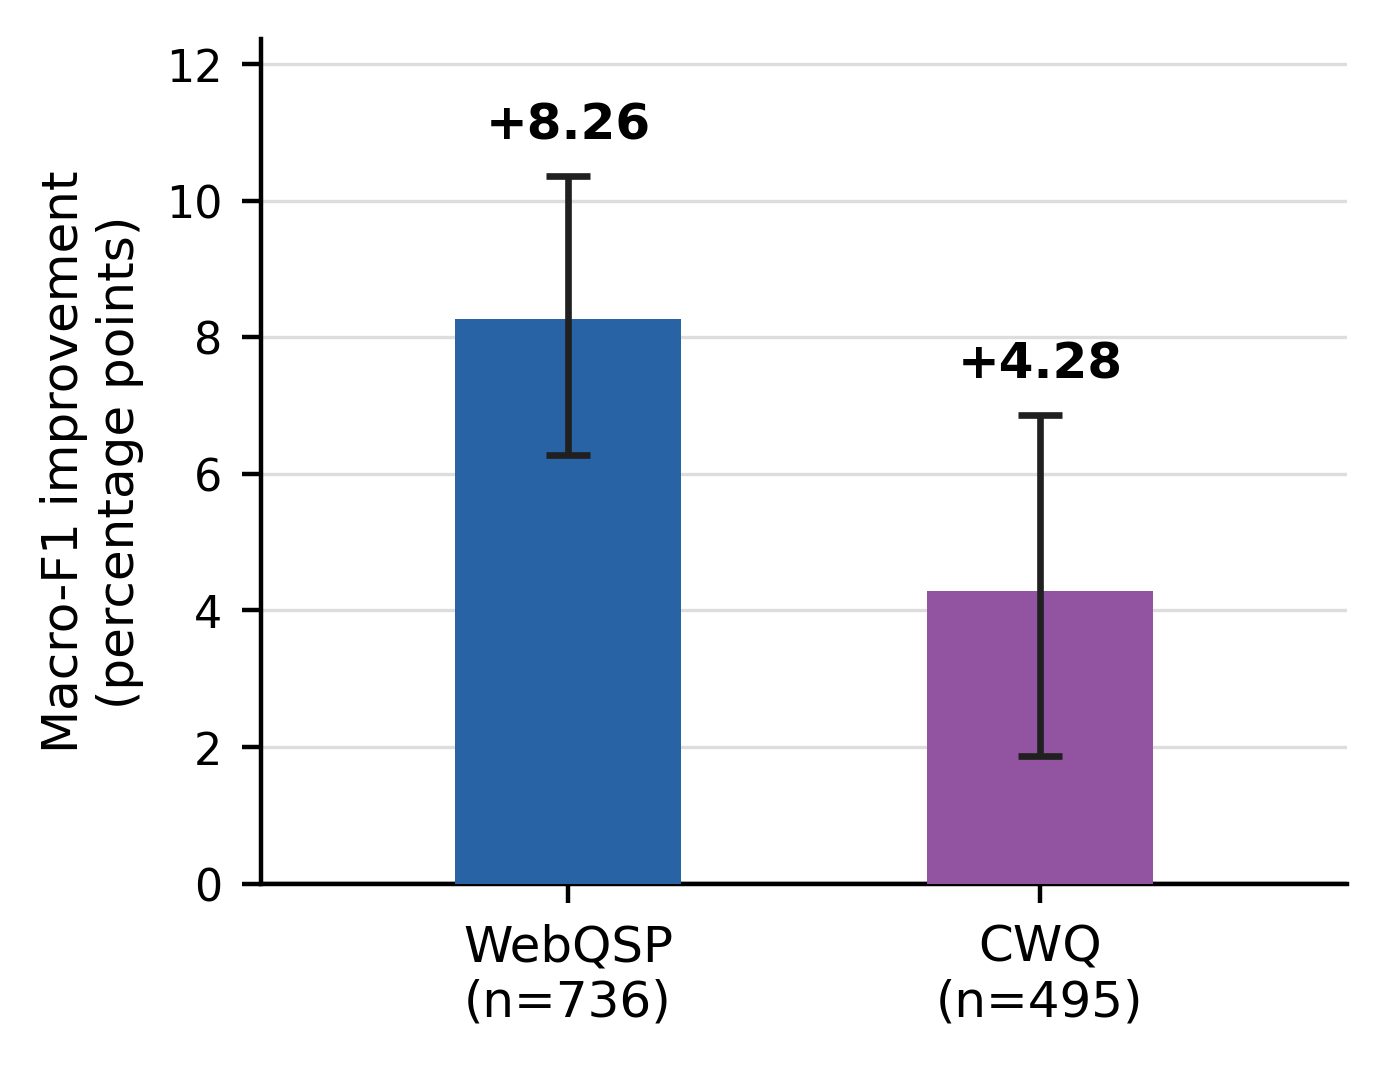

In [4]:
from pathlib import Path
import hashlib
import json
from IPython.display import Image, display

OUT = Path(
    "/content/drive/MyDrive/SetStop_KGQA/"
    "outputs/two_dataset_paper_results_v1"
)

summary_path = OUT / "two_dataset_paper_summary_v1.json"
inventory_path = OUT / "artifact_inventory_v1.json"

for path in [summary_path, inventory_path]:
    if not path.exists():
        raise FileNotFoundError(
            f"Expected output is missing: {path}"
        )

summary = json.loads(summary_path.read_text(encoding="utf-8"))
inventory = json.loads(inventory_path.read_text(encoding="utf-8"))

assert summary["question_counts"] == {"WebQSP": 736, "CWQ": 495}
assert summary["model_inference_performed"] is False
assert summary["thresholds_modified"] is False

# Verify every generated artifact against its saved checksum.
for entry in inventory["files"]:
    path = OUT / entry["relative_path"]

    assert path.exists(), f"Missing artifact: {path}"
    assert path.stat().st_size == entry["bytes"], (
        f"File size mismatch: {path}"
    )

    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    assert digest.hexdigest() == entry["sha256"], (
        f"Checksum mismatch: {path}"
    )

print("VERIFICATION PASSED")
print("All generated artifact sizes and checksums match.\n")

print("Matched-budget comparisons:")
for dataset, values in summary["matched_comparisons"].items():
    difference = values["differences"]["macro_f1"]
    low, high = difference["ci95"]

    print(
        f"{dataset}: "
        f"fixed-ranker F1={values['fixed_ranker']['macro_f1']:.4f}, "
        f"SetStop F1={values['setstop']['macro_f1']:.4f}"
    )
    print(
        f"  Improvement: {100 * difference['difference']:+.2f} points"
        f"; paired 95% CI [{100 * low:+.2f}, {100 * high:+.2f}]"
    )

print("\nSEND THESE FOUR FILES:")
for relative_path in [
    "two_dataset_paper_summary_v1.json",
    "matched_budget_comparisons_v1.json",
    "figures/matched_budget_f1_improvements_v1.png",
    "artifact_inventory_v1.json",
]:
    print(OUT / relative_path)

print("\nACL bundle:", OUT / "acl_results_bundle_v1.zip")

display(Image(
    filename=str(
        OUT / "figures/matched_budget_f1_improvements_v1.png"
    ),
    width=550,
))